In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, f_oneway

sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

# Load the cleaned dataset
df = pd.read_csv('cleaned_dataset.csv')
print("Cleaned Dataset Loaded Successfully! Shape:", df.shape)

Cleaned Dataset Loaded Successfully! Shape: (129880, 22)


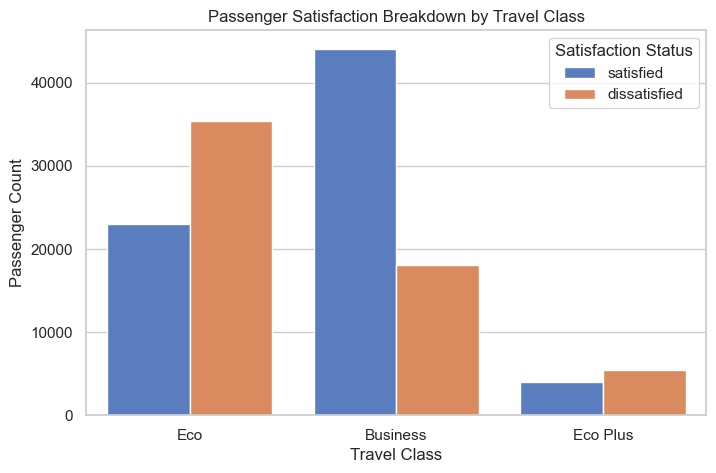

--- Percentage Satisfaction by Class ---
satisfaction  dissatisfied  satisfied
Class                                
Business         29.062098  70.937902
Eco              60.601279  39.398721
Eco Plus         57.294655  42.705345


In [2]:
# Segment-specific analysis (Business vs Eco satisfaction comparison)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Class', hue='satisfaction', palette='muted')
plt.title('Passenger Satisfaction Breakdown by Travel Class')
plt.xlabel('Travel Class')
plt.ylabel('Passenger Count')
plt.legend(title='Satisfaction Status')
plt.show()

# Percentage breakdown by class
class_satisfaction_pct = pd.crosstab(df['Class'], df['satisfaction'], normalize='index') * 100
print("--- Percentage Satisfaction by Class ---")
print(class_satisfaction_pct)

In [3]:
# Chi-Square Test for Categorical Features against Satisfaction
# Testing 'Customer Type' and 'Type of Travel' with 'satisfaction'

print("--- Chi-Square Test: Customer Type vs Satisfaction ---")
contingency_table_1 = pd.crosstab(df['Customer Type'], df['satisfaction'])
chi2_1, p_1, dof_1, ex_1 = chi2_contingency(contingency_table_1)
print(f"Chi2 Statistic: {chi2_1:.4f}")
print(f"p-value: {p_1:.4e}")

print("\n--- Chi-Square Test: Type of Travel vs Satisfaction ---")
contingency_table_2 = pd.crosstab(df['Type of Travel'], df['satisfaction'])
chi2_2, p_2, dof_2, ex_2 = chi2_contingency(contingency_table_2)
print(f"Chi2 Statistic: {chi2_2:.4f}")
print(f"p-value: {p_2:.4e}")

--- Chi-Square Test: Customer Type vs Satisfaction ---
Chi2 Statistic: 11117.5360
p-value: 0.0000e+00

--- Chi-Square Test: Type of Travel vs Satisfaction ---
Chi2 Statistic: 1549.3964
p-value: 0.0000e+00


In [4]:
# ANOVA Test for Numerical Service Ratings against Satisfaction
# Grouping ratings by satisfaction status to check variance
rating_cols = ['Seat comfort', 'Departure/Arrival time convenient', 'Food and drink', 
               'Gate location', 'Inflight wifi service', 'Inflight entertainment', 
               'Online support', 'Ease of Online booking', 'On-board service', 
               'Leg room service', 'Baggage handling', 'Checkin service', 
               'Cleanliness', 'Online boarding']

anova_results = []
for col in rating_cols:
    satisfied_group = df[df['satisfaction'] == 'satisfied'][col]
    dissatisfied_group = df[df['satisfaction'] == 'dissatisfied'][col]
    
    f_stat, p_val = f_oneway(satisfied_group, dissatisfied_group)
    anova_results.append({'Feature': col, 'F-Statistic': f_stat, 'p-value': p_val})

anova_df = pd.DataFrame(anova_results).sort_values(by='F-Statistic', ascending=False)
print("--- ANOVA Test Results for Service Ratings ---")
display(anova_df)

--- ANOVA Test Results for Service Ratings ---


,Feature,F-Statistic,p-value
5,Inflight entertainment,49029.186435,0.000000e+00
7,Ease of Online booking,29761.100914,0.000000e+00
6,Online support,23318.295343,0.000000e+00
8,On-board service,18373.892244,0.000000e+00
13,Online boarding,16767.987473,0.000000e+00
9,Leg room service,13314.115992,0.000000e+00
11,Checkin service,9903.689497,0.000000e+00
10,Baggage handling,9443.249280,0.000000e+00
12,Cleanliness,9364.298000,0.000000e+00
0,Seat comfort,8106.626158,0.000000e+00


--- Average Delay Minutes by Satisfaction Status ---


,Departure Delay in Minutes,Arrival Delay in Minutes
satisfaction,,
dissatisfied,17.807749,18.445427
satisfied,12.154768,12.233503


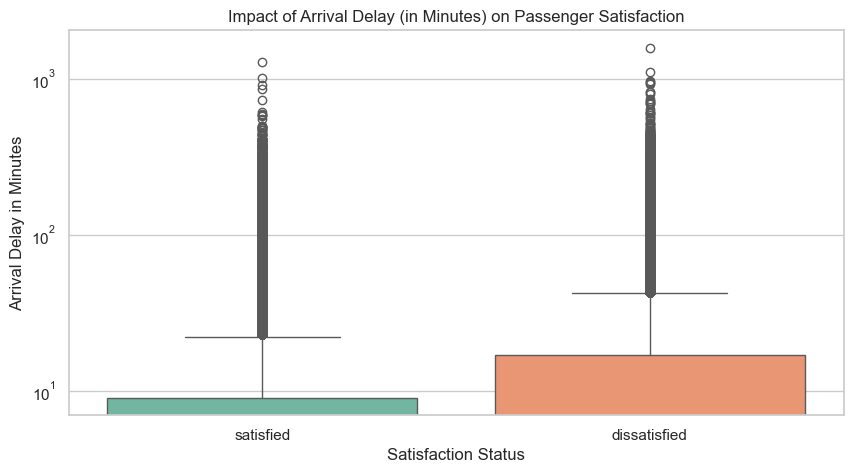

In [5]:
# Analyzing the impact of Departure and Arrival Delays on Satisfaction
delay_summary = df.groupby('satisfaction')[['Departure Delay in Minutes', 'Arrival Delay in Minutes']].mean()
print("--- Average Delay Minutes by Satisfaction Status ---")
display(delay_summary)

# Visualizing delay distribution impact
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='satisfaction', y='Arrival Delay in Minutes', palette='Set2')
plt.title('Impact of Arrival Delay (in Minutes) on Passenger Satisfaction')
plt.xlabel('Satisfaction Status')
plt.ylabel('Arrival Delay in Minutes')
plt.yscale('log')  # Using log scale due to high outlier values in delays
plt.show()

In [6]:
# Feature Engineering (Creating Total_Delay and encoding variables)
# Create a combined Total Delay feature
df['Total_Delay'] = df['Departure Delay in Minutes'] + df['Arrival Delay in Minutes']

# Map categorical target and key features to numerical values for modeling readiness
df['satisfaction_encoded'] = df['satisfaction'].map({'satisfied': 1, 'dissatisfied': 0})
df['Customer Type encoded'] = df['Customer Type'].map({'Loyal Customer': 1, 'disloyal Customer': 0})
df['Type of Travel encoded'] = df['Type of Travel'].map({'Business travel': 1, 'Personal Travel': 0})

# Drop original non-numeric or redundant columns if needed, and check the columns/shape
processed_df = df.drop(columns=['satisfaction', 'Customer Type', 'Type of Travel'], errors='ignore')

print("Feature Engineering Completed Successfully!")
print("New Shape of Processed DataFrame:", processed_df.shape)
print("\nFirst 5 rows of newly engineered columns:")
display(processed_df[['Total_Delay', 'satisfaction_encoded', 'Customer Type encoded', 'Type of Travel encoded']].head())

Feature Engineering Completed Successfully!
New Shape of Processed DataFrame: (129880, 23)

First 5 rows of newly engineered columns:


,Total_Delay,satisfaction_encoded,Customer Type encoded,Type of Travel encoded
0,0.0,1,1,0
1,615.0,1,1,0
2,0.0,1,1,0
3,0.0,1,1,0
4,0.0,1,1,0


In [7]:
# Save the verified processed dataset for model training
processed_df.to_csv('processed_satisfaction_data.csv', index=False)
print("Processed Dataset Successfully Saved as 'processed_satisfaction_data.csv'! Shape:", processed_df.shape)

Processed Dataset Successfully Saved as 'processed_satisfaction_data.csv'! Shape: (129880, 23)
